In [2]:
from pathlib import Path
import json, platform
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
import sklearn

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_absolute_error

In [3]:
# load week 3 export and define features
summary = json.load(open("02_run_summary.json"))
best_X, test_month = summary["best_X"], summary["test_month"]
low, high = summary["lower_threshold"], summary["upper_threshold"]

numeric_features = ["LivingArea", "BedroomsTotal", "BathroomsTotalInteger", "LotSizeSquareFeet",
                    "YearBuilt", "Latitude", "Longitude", "ParkingTotal"]
categorical_features = ["PostalCode", "FireplaceYN", "NewConstructionYN", "City",
                        "CountyOrParish", "ViewYN", "MLSAreaMajor", "AttachedGarageYN"]
features = numeric_features + categorical_features
target = "ClosePrice"

# PostalCode must be read as text, otherwise it becomes a float and "92253" turns into "92253.0"
df = pd.read_csv("02_cleaned_data.csv", dtype={"PostalCode": "string"},
                 parse_dates=["CloseDate"], low_memory=False)
train = df[df["dataset_split"] == "train"].copy()
test = df[df["dataset_split"] == "test"].copy()

# Same categorical handling as Week 3
for d in (train, test):
    for c in categorical_features:
        d[c] = d[c].astype("string").fillna("Missing")

X_train, y_train = train[features], train[target].to_numpy(float)
X_test, y_test = test[features], test[target].to_numpy(float)

print(f"Training window: {best_X} months | test month: {test_month}")
print(f"Train: {X_train.shape} | Test: {X_test.shape}")
print(f"Training price bounds: ${low:,.0f} to ${high:,.0f}")

Training window: 9 months | test month: 2026-04
Train: (264546, 16) | Test: (12328, 16)
Training price bounds: $200,000 to $8,287,983


In [4]:
# re-build linear regression pipeline
numeric_transformer = Pipeline([("imputer", SimpleImputer(strategy="median")),
                                ("scaler", StandardScaler())])
categorical_transformer = Pipeline([("imputer", SimpleImputer(strategy="constant", fill_value="Missing")),
                                    ("onehot", OneHotEncoder(handle_unknown="ignore"))])
preprocessor = ColumnTransformer([("num", numeric_transformer, numeric_features),
                                  ("cat", categorical_transformer, categorical_features)])
baseline_pipeline = Pipeline([("preprocessor", preprocessor), ("model", LinearRegression())])

In [11]:
# Predict the training median price for every home
pred_median = np.full(len(y_test), np.median(y_train))

# Predict the training median price for every home
pred_median = np.full(len(y_test), np.median(y_train))

# $/sqft from training rows with valid area only
train_valid = train[train["LivingArea"] > 0]
median_ppsf = (train_valid["ClosePrice"] / train_valid["LivingArea"]).median()

# fall back to the training median price when LivingArea is missing
pred_ppsf = (median_ppsf * test["LivingArea"]).fillna(train["ClosePrice"].median())
pred_ppsf = pred_ppsf.to_numpy()

In [12]:
# fit model on log prices (ClosePrice heavily right skewed) 
baseline_model = baseline_pipeline.fit(X_train, np.log(y_train))
y_pred = np.exp(baseline_model.predict(X_test))   # back to dollars, always positive

assert np.isfinite(y_pred).all() and (y_pred > 0).all()
print("Encoded features:", baseline_model.named_steps["preprocessor"].get_feature_names_out().shape[0])

Encoded features: 5107


In [16]:
# metrics for the baseline and references
def metrics(y, p):
    ape = np.abs(p - y) / y * 100
    return {"n": len(y),
            "MdAPE_pct": np.median(ape),                  # headline metric
            "MAPE_pct": ape.mean(),
            "R2": r2_score(y, p),
            "MAE": mean_absolute_error(y, p),
            "RMSE": np.sqrt(np.mean((y - p) ** 2)),
            "within_10pct": (ape <= 10).mean() * 100,
            "median_bias_pct": np.median((p - y) / y * 100)}

results = pd.DataFrame({
    "Reference: training median price": metrics(y_test, pred_median),
    "Reference: median $/sqft x living area": metrics(y_test, pred_ppsf),
    "Baseline: Linear Regression (log target)": metrics(y_test, y_pred)}).T
display(results.round(3))

,n,MdAPE_pct,MAPE_pct,R2,MAE,RMSE,within_10pct,median_bias_pct
Reference: training median price,12328.0,40.067,50.273,-0.115,610084.531,1034674.818,13.757,-1.749
Reference: median $/sqft x living area,12328.0,35.719,47.567,0.337,514503.571,797816.521,14.203,-1.329
Baseline: Linear Regression (log target),12328.0,9.984,14.095,0.755,196001.870,485002.701,50.089,-1.380


In [17]:
val_mdape = summary["validation_mean_MdAPE"]
test_mdape = results.loc["Baseline: Linear Regression (log target)", "MdAPE_pct"]
print(f"Validation mean MdAPE (Jan-Mar window selection): {val_mdape:.2f}%")
print(f"April test MdAPE:                                  {test_mdape:.2f}%")

Validation mean MdAPE (Jan-Mar window selection): 9.93%
April test MdAPE:                                  9.98%


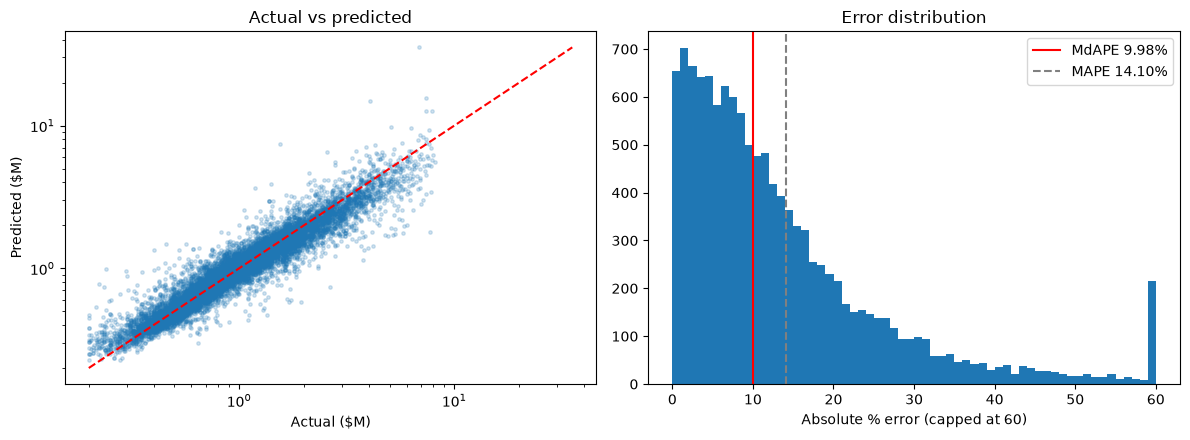

In [18]:
preds = test[["CloseDate", "City", "CountyOrParish", "PostalCode"]].copy()
preds["ActualClosePrice"] = y_test
preds["PredictedClosePrice"] = y_pred
preds["Residual"] = y_test - y_pred
preds["APE_pct"] = np.abs(y_pred - y_test) / y_test * 100

fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
ax[0].scatter(y_test / 1e6, y_pred / 1e6, s=6, alpha=0.2)
lim = [min(y_test.min(), y_pred.min()) / 1e6, max(y_test.max(), y_pred.max()) / 1e6]
ax[0].plot(lim, lim, "r--"); ax[0].set(xscale="log", yscale="log", xlabel="Actual ($M)",
                                       ylabel="Predicted ($M)", title="Actual vs predicted")
ax[1].hist(preds["APE_pct"].clip(upper=60), bins=60)
ax[1].axvline(preds["APE_pct"].median(), color="r", label=f"MdAPE {preds['APE_pct'].median():.2f}%")
ax[1].axvline(preds["APE_pct"].mean(), color="gray", ls="--", label=f"MAPE {preds['APE_pct'].mean():.2f}%")
ax[1].set(xlabel="Absolute % error (capped at 60)", title="Error distribution"); ax[1].legend()
fig.tight_layout(); plt.show()

In [19]:
def group_report(by):
    g = preds.groupby(by, observed=True)
    out = pd.DataFrame({"n": g.size(), "median_price": g["ActualClosePrice"].median(),
                        "MdAPE_pct": g["APE_pct"].median(), "MAPE_pct": g["APE_pct"].mean(),
                        "median_bias_pct": g.apply(lambda d: np.median((d.PredictedClosePrice - d.ActualClosePrice)
                                                                        / d.ActualClosePrice * 100))})
    return out

preds["price_quintile"] = pd.qcut(preds["ActualClosePrice"], 5, labels=["Q1 low", "Q2", "Q3", "Q4", "Q5 high"])
by_band = group_report("price_quintile")
by_county = group_report("CountyOrParish").query("n >= 100").sort_values("n", ascending=False)
display(by_band.round(2)); display(by_county.round(2))

,n,median_price,MdAPE_pct,MAPE_pct,median_bias_pct
price_quintile,,,,,
Q1 low,2501,450000.0,9.45,15.53,3.55
Q2,2483,699000.0,8.50,11.99,0.50
Q3,2503,925000.0,8.81,11.74,0.40
Q4,2375,1330000.0,10.28,13.27,-3.57
Q5 high,2466,2350000.0,14.35,17.94,-10.34


,n,median_price,MdAPE_pct,MAPE_pct,median_bias_pct
CountyOrParish,,,,,
Los Angeles,3020,1017500.0,10.08,14.07,-1.39
Riverside,1879,638000.0,9.72,14.40,-0.02
San Diego,1448,1095000.0,10.54,14.33,-1.68
San Bernardino,1234,554450.0,8.67,12.23,-1.10
Orange,1175,1440000.0,9.34,12.84,-3.79
Alameda,590,1323000.0,12.50,16.61,-3.53
Contra Costa,583,900000.0,10.19,13.26,-0.60
Ventura,419,999009.0,9.65,13.84,-2.33
Santa Clara,406,1934500.0,10.60,14.63,-2.25


In [22]:
roll = pd.read_csv("02_cleaned_data.csv", dtype={"PostalCode": "string"}, parse_dates=["CloseDate"], low_memory=False)
# Only works if you export all months; otherwise quote the validation table from Week 3.

In [24]:
# Headline result 
b = results.loc["Baseline: Linear Regression (log target)"]
print("=" * 60)
print("WEEK 4 BASELINE: LINEAR REGRESSION (log target)")
print("=" * 60)
print(f"Training window : {best_X} months  |  test month: {test_month}")
print(f"Train rows      : {len(train):,}   |  test rows: {len(test):,}")
print(f"Price bounds    : ${low:,.0f} to ${high:,.0f}")
print(f"Encoded columns : {baseline_model.named_steps['preprocessor'].get_feature_names_out().shape[0]:,}")
print("-" * 60)
print(f"MdAPE (headline): {b['MdAPE_pct']:.2f}%")
print(f"R2              : {b['R2']:.4f}")
print(f"MAPE            : {b['MAPE_pct']:.2f}%")
print(f"MAE / RMSE      : ${b['MAE']:,.0f} / ${b['RMSE']:,.0f}")
print(f"Within 10%      : {b['within_10pct']:.1f}% of homes")
print(f"Median bias     : {b['median_bias_pct']:+.2f}%")
print(f"Validation MdAPE (Week 3, mean): {val_mdape:.2f}%")

# Baseline vs no-model references 
print("\nBASELINE VS NO-MODEL REFERENCES")
display(results.round(3))

# Error by price quintile and county
print("\nERROR BY PRICE QUINTILE")
display(by_band.round(2))
print("\nERROR BY COUNTY (100+ April sales)")
display(by_county.round(2))

# Sample of predictions (best, typical, worst)
print("\nSAMPLE PREDICTIONS")
sample = pd.concat([preds.nsmallest(3, "APE_pct"),
                    preds.iloc[(preds["APE_pct"] - preds["APE_pct"].median()).abs().argsort()[:3]],
                    preds.nlargest(3, "APE_pct")])
sample.insert(0, "case", ["best"] * 3 + ["typical"] * 3 + ["worst"] * 3)
display(sample[["case", "City", "CountyOrParish", "ActualClosePrice",
                "PredictedClosePrice", "APE_pct"]].round(1))

# Diagnostic plots 
plt.show()


WEEK 4 BASELINE: LINEAR REGRESSION (log target)
Training window : 9 months  |  test month: 2026-04
Train rows      : 264,546   |  test rows: 12,328
Price bounds    : $200,000 to $8,287,983
Encoded columns : 5,107
------------------------------------------------------------
MdAPE (headline): 9.98%
R2              : 0.7550
MAPE            : 14.10%
MAE / RMSE      : $196,002 / $485,003
Within 10%      : 50.1% of homes
Median bias     : -1.38%
Validation MdAPE (Week 3, mean): 9.93%

BASELINE VS NO-MODEL REFERENCES


,n,MdAPE_pct,MAPE_pct,R2,MAE,RMSE,within_10pct,median_bias_pct
Reference: training median price,12328.0,40.067,50.273,-0.115,610084.531,1034674.818,13.757,-1.749
Reference: median $/sqft x living area,12328.0,35.719,47.567,0.337,514503.571,797816.521,14.203,-1.329
Baseline: Linear Regression (log target),12328.0,9.984,14.095,0.755,196001.870,485002.701,50.089,-1.380



ERROR BY PRICE QUINTILE


,n,median_price,MdAPE_pct,MAPE_pct,median_bias_pct
price_quintile,,,,,
Q1 low,2501,450000.0,9.45,15.53,3.55
Q2,2483,699000.0,8.50,11.99,0.50
Q3,2503,925000.0,8.81,11.74,0.40
Q4,2375,1330000.0,10.28,13.27,-3.57
Q5 high,2466,2350000.0,14.35,17.94,-10.34



ERROR BY COUNTY (100+ April sales)


,n,median_price,MdAPE_pct,MAPE_pct,median_bias_pct
CountyOrParish,,,,,
Los Angeles,3020,1017500.0,10.08,14.07,-1.39
Riverside,1879,638000.0,9.72,14.40,-0.02
San Diego,1448,1095000.0,10.54,14.33,-1.68
San Bernardino,1234,554450.0,8.67,12.23,-1.10
Orange,1175,1440000.0,9.34,12.84,-3.79
Alameda,590,1323000.0,12.50,16.61,-3.53
Contra Costa,583,900000.0,10.19,13.26,-0.60
Ventura,419,999009.0,9.65,13.84,-2.33
Santa Clara,406,1934500.0,10.60,14.63,-2.25



SAMPLE PREDICTIONS


,case,City,CountyOrParish,ActualClosePrice,PredictedClosePrice,APE_pct
273151,best,Torrance,Los Angeles,849000.0,848993.6,0.0
274504,best,Palm Springs,Riverside,710000.0,709988.1,0.0
270731,best,Chula Vista,San Diego,1255000.0,1255031.9,0.0
271601,typical,Adelanto,San Bernardino,449900.0,404983.6,10.0
271630,typical,Chico,Butte,649000.0,584205.6,10.0
269933,typical,Yorba Linda,Orange,1425000.0,1282778.2,10.0
268585,worst,Encino,Los Angeles,6835000.0,35325217.3,416.8
276289,worst,Granada Hills,Los Angeles,1550000.0,7403855.0,377.7
265797,worst,San Marcos,San Diego,240000.0,981031.7,308.8
